Pada Notebook ini Fold Traing (p1) dan Foldd Testing (p2) sebagai berikt:

>P1= "12/06/2015 - 21/06/2015"


>p2= "22/06/2015 - 01/07/2015"

In [1]:
from neo4j import GraphDatabase, RoutingControl
import pandas as pd
from tqdm import tqdm
import math
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import sparse

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "password")
DATABASE = "neo4j"

driver = GraphDatabase.driver(URI, auth=AUTH)
session = driver.session(database="system")

RAW_PATH = "../UTS/Local_data/events.csv"
OUT_DIR = "../UTS/Data"


# 2.1   

## 1. Filter data set 

In [2]:
PERIODS = {
    "P1": ("2015-06-12", "2015-06-21"),   # 12/06/2015 - 21/06/2015
    "P2": ("2015-06-22", "2015-07-01"),   # 22/06/2015 - 01/07/2015
}

df = pd.read_csv(RAW_PATH, dtype={"transactionid": "string"})
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)  # zona waktu: UTC

result = {}
for name, (start, end) in PERIODS.items():
    lo = pd.Timestamp(start, tz="UTC")
    hi = pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1)  # tanggal akhir ikut penuh
    part = df[(df["datetime"] >= lo) & (df["datetime"] < hi)].copy()
    part["period"] = name
    part["datetime"] = part["datetime"].dt.strftime("%Y-%m-%d %H:%M:%S")
    part.to_csv(f"{OUT_DIR}/events_{name}.csv", index=False)
    result[name] = part

# --- pengecekan ---
for name, part in result.items():
    print(name, "| baris:", len(part),
          "| visitor:", part["visitorid"].nunique(),
          "| item:", part["itemid"].nunique())
    print(part["event"].value_counts().to_string(), "\n")

v1, v2 = set(result["P1"]["visitorid"]), set(result["P2"]["visitorid"])
i1, i2 = set(result["P1"]["itemid"]), set(result["P2"]["itemid"])
print("Visitor di kedua periode:", len(v1 & v2))
print("Item di kedua periode   :", len(i1 & i2))

P1 | baris: 188267 | visitor: 99659 | item: 59808
event
view           181674
addtocart        5002
transaction      1591 

P2 | baris: 206884 | visitor: 110012 | item: 64577
event
view           200049
addtocart        5053
transaction      1782 

Visitor di kedua periode: 4777
Item di kedua periode   : 31454


In [3]:
FILES = {
    "P1": f"{OUT_DIR}/events_P1.csv",
    "P2": f"{OUT_DIR}/events_P2.csv",
}
BATCH_SIZE = 5000
RESET_DB = False   

In [4]:
def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    ).consume()

    session.run(
        "CREATE CONSTRAINT item_id_unique IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    ).consume()

    session.run(
        "CREATE CONSTRAINT transaction_id_unique IF NOT EXISTS "
        "FOR (t:Transaction) REQUIRE t.transactionId IS UNIQUE"
    ).consume()

    session.run(
        "CREATE CONSTRAINT category_id_unique IF NOT EXISTS "
        "FOR (c:Category) REQUIRE c.categoryId IS UNIQUE"
    ).consume()


In [5]:
Q_VIEW = """
UNWIND $rows AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:VIEWED {timestamp: row.timestamp, period: row.period}]->(i)
"""

Q_CART = """
UNWIND $rows AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, period: row.period}]->(i)
"""

Q_BUY = """
UNWIND $rows AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
MERGE (t:Transaction {transactionId: row.transactionid})
CREATE (v)-[:BOUGHT {timestamp: row.timestamp, period: row.period,
                     transactionId: row.transactionid}]->(i)
MERGE (v)-[:MADE]->(t)
MERGE (t)-[:CONTAINS]->(i)
"""

Q_EXISTS = "MATCH ()-[r]->() WHERE r.period = $period RETURN count(r) AS n"



In [6]:
def import_batch(tx, records):
    views = [r for r in records if r["event"] == "view"]
    carts = [r for r in records if r["event"] == "addtocart"]
    buys = [r for r in records if r["event"] == "transaction" and r["transactionid"]]
    if views:
        tx.run(Q_VIEW, rows=views).consume()
    if carts:
        tx.run(Q_CART, rows=carts).consume()
    if buys:
        tx.run(Q_BUY, rows=buys).consume()


def count_rows(path):
    with open(path, "r", encoding="utf-8") as f:
        return sum(1 for _ in f) - 1   # kurangi baris header


def import_file(session, period, path):
    existing = session.execute_read(
        lambda tx: tx.run(Q_EXISTS, period=period).single()["n"]
    )
    if existing:
        raise RuntimeError(
            f"Periode {period} sudah ada di graf ({existing} relasi). "
            "Impor dibatalkan agar tidak terduplikasi."
        )

    total_rows = count_rows(path)
    total_chunks = -(-total_rows // BATCH_SIZE)   # pembulatan ke atas
    print(f"[{period}] membaca {path} ({total_rows} baris)")

    chunks = pd.read_csv(path, chunksize=BATCH_SIZE, dtype={"transactionid": "string"})
    skipped = 0
    for chunk in tqdm(chunks, total=total_chunks, desc=f"Impor {period}"):
        # Membersihkan data null/NaN pada transactionid
        chunk["transactionid"] = chunk["transactionid"].fillna("")
        skipped += int(((chunk["event"] == "transaction") & (chunk["transactionid"] == "")).sum())
        records = chunk.astype(object).to_dict(orient="records")  # tipe Python native
        session.execute_write(import_batch, records)

    print(f"[{period}] selesai. Baris transaksi tanpa id yang dilewati: {skipped}")


In [7]:
driver = GraphDatabase.driver(URI, auth=AUTH)
try:
    driver.verify_connectivity()
    with driver.session(database=DATABASE) as session:
        if RESET_DB:
            session.run("MATCH (n) DETACH DELETE n").consume()
        create_constraints(session)
        for period, path in FILES.items():
            import_file(session, period, path)
    print("Proses impor berhasil.")
finally:
    driver.close()


[P1] membaca ../UTS/Data/events_P1.csv (188267 baris)


Impor P1: 100%|██████████| 38/38 [00:30<00:00,  1.25it/s]


[P1] selesai. Baris transaksi tanpa id yang dilewati: 0
[P2] membaca ../UTS/Data/events_P2.csv (206884 baris)


Impor P2: 100%|██████████| 42/42 [00:21<00:00,  1.96it/s]

[P2] selesai. Baris transaksi tanpa id yang dilewati: 0
Proses impor berhasil.


4. 

In [8]:
WEIGHTS = {"VIEWED": 1, "ADDED_TO_CART": 2, "BOUGHT": 3}

Q_USER_ITEM = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.period = $period
RETURN v.visitorId AS user, i.itemId AS item, type(r) AS event, count(*) AS n
"""



In [9]:
def build_user_vsm(session, period):
    rows = session.execute_read(lambda tx: tx.run(Q_USER_ITEM, period=period).data())
    df = pd.DataFrame(rows)
    df["w"] = df["event"].map(WEIGHTS) * df["n"]
    agg = df.groupby(["user", "item"], as_index=False)["w"].sum()

    u_cat = agg["user"].astype("category")
    i_cat = agg["item"].astype("category")
    X = sparse.csr_matrix(
        (agg["w"].to_numpy(dtype=float), (u_cat.cat.codes, i_cat.cat.codes)),
        shape=(len(u_cat.cat.categories), len(i_cat.cat.categories)),
    )
    return X, u_cat.cat.categories.to_numpy(), i_cat.cat.categories.to_numpy()

In [10]:
def describe_vsm(X, name):
    n_users, n_items = X.shape
    deg = np.diff(X.indptr)                       # jumlah item berbeda per user
    sparse_mb = (X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6
    return pd.Series({
        "shape (user x item)": f"{n_users} x {n_items}",
        "dimensi vektor user": n_items,
        "elemen tak-nol": X.nnz,
        "density (%)": round(100 * X.nnz / (n_users * n_items), 4),
        "sparsity (%)": round(100 - 100 * X.nnz / (n_users * n_items), 4),
        "item/user rata-rata": round(deg.mean(), 2),
        "item/user median": float(np.median(deg)),
        "item/user persentil 95": float(np.percentile(deg, 95)),
        "item/user maks": int(deg.max()),
        "user dengan 1 item (%)": round(100 * (deg == 1).mean(), 2),
        "ukuran sparse (MB)": round(sparse_mb, 2),
        "ukuran dense jika dimaterialisasi (GB)": round(n_users * n_items * 8 / 1e9, 2),
    }, name=name)

In [11]:
def plot_sample(X, users, items, title, ax, n_top_items=10, n_users=40, seed=42):
    rng = np.random.default_rng(seed)
    item_deg = np.diff(X.tocsc().indptr)
    top_items = np.argsort(item_deg)[::-1][:n_top_items]
    sub = X[:, top_items]
    candidates = np.unique(sub.nonzero()[0])
    chosen = rng.choice(candidates, size=min(n_users, len(candidates)), replace=False)
    sub = sub[chosen]

    u_nodes = [f"u{users[r]}" for r in chosen]
    i_nodes = [f"i{items[c]}" for c in top_items]
    G = nx.Graph()
    G.add_nodes_from(u_nodes, bipartite=0)
    G.add_nodes_from(i_nodes, bipartite=1)
    r_idx, c_idx = sub.nonzero()
    G.add_edges_from((u_nodes[r], i_nodes[c]) for r, c in zip(r_idx, c_idx))

    pos = nx.bipartite_layout(G, u_nodes)
    nx.draw_networkx_nodes(G, pos, nodelist=u_nodes, node_color="tab:blue",
                           node_size=60, label="User", ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=i_nodes, node_color="tab:orange",
                           node_size=120, label="Item", ax=ax)
    nx.draw_networkx_edges(G, pos, alpha=0.3, ax=ax)
    ax.set_title(title)
    ax.legend()
    ax.axis("off")


def plot_degree_hist(X, title, ax, bins, xlabel, ylabel):
    deg = np.diff(X.indptr)
    ax.hist(deg, bins=bins, log=True)
    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

In [12]:
results = {}
with driver.session(database="neo4j") as session:
    for p in ["P1", "P2"]:
        results[p] = build_user_vsm(session, p)
        print(p, "-> shape:", results[p][0].shape, "| nnz:", results[p][0].nnz)

C:\Users\Hype\AppData\Local\Temp\ipykernel_3340\199761499.py:2: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


P1 -> shape: (99659, 59808) | nnz: 146519
P2 -> shape: (110012, 64577) | nnz: 161406


In [13]:
summary = pd.DataFrame([describe_vsm(results[p][0], p) for p in results]).T
summary

,P1,P2
shape (user x item),99659 x 59808,110012 x 64577
dimensi vektor user,59808,64577
elemen tak-nol,146519,161406
density (%),0.0025,0.0023
sparsity (%),99.9975,99.9977
item/user rata-rata,1.47,1.47
item/user median,1.0,1.0
item/user persentil 95,3.0,3.0
item/user maks,455,657
user dengan 1 item (%),81.37,81.35


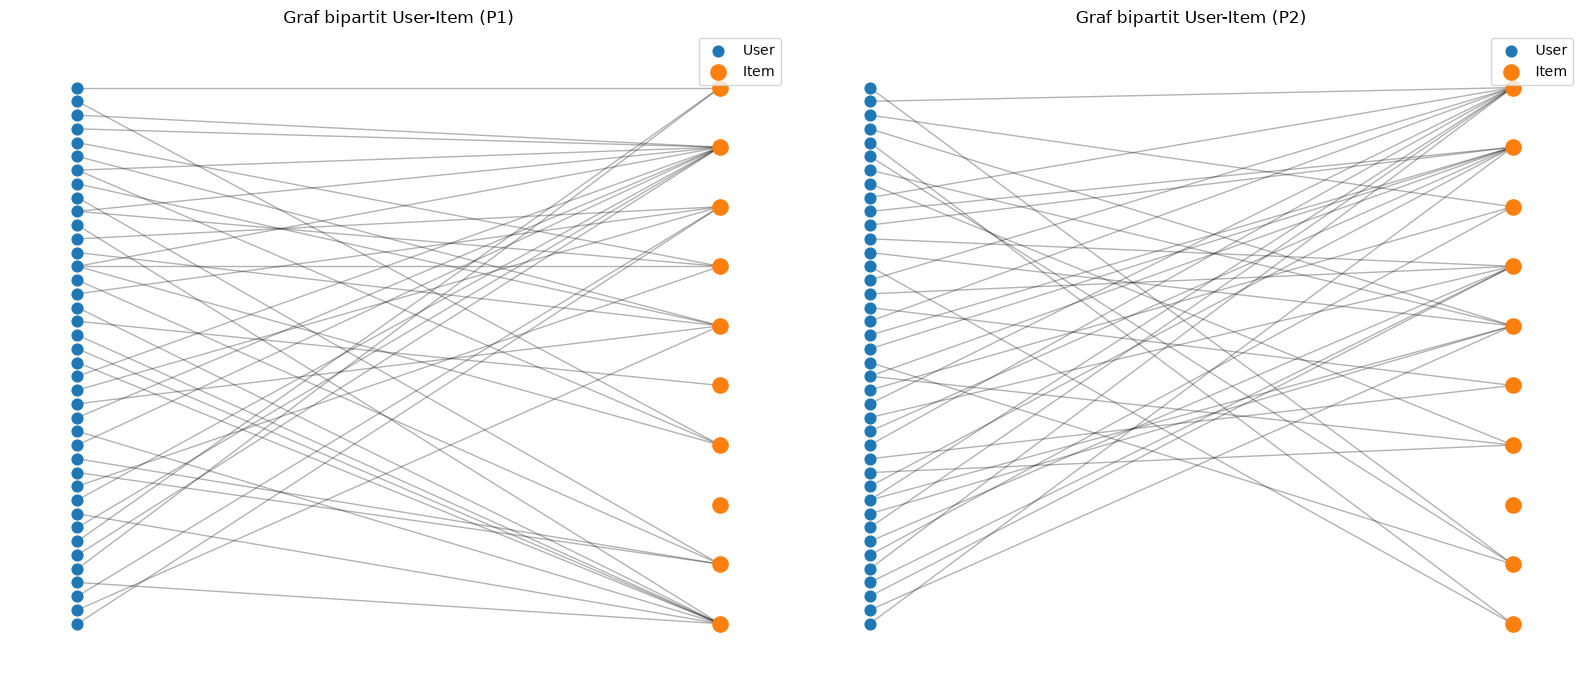

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, p in zip(axes, results):
    X, users, items = results[p]
    plot_sample(X, users, items, f"Graf bipartit User-Item ({p})", ax)
plt.tight_layout()
plt.show()

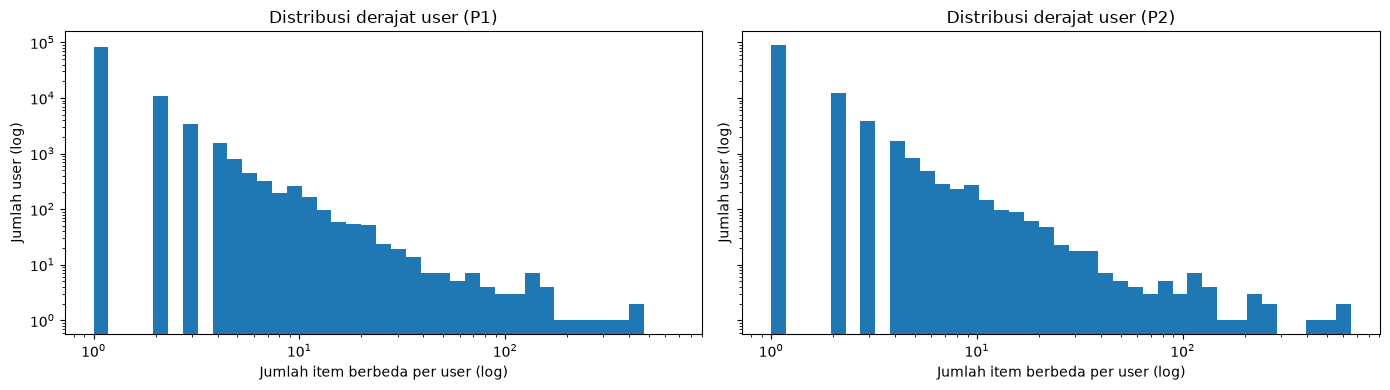

In [15]:
max_deg = max(np.diff(results[p][0].indptr).max() for p in results)
bins = np.logspace(0, np.log10(max_deg), 40)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True, sharey=True)
for ax, p in zip(axes, results):
    plot_degree_hist(results[p][0], f"Distribusi derajat user ({p})", ax, bins,
                     "Jumlah item berbeda per user (log)", "Jumlah user (log)")
plt.tight_layout()
plt.show()

In [16]:
def describe_item_vsm(Xi, name):
    n_items, n_users = Xi.shape
    deg = np.diff(Xi.indptr)                      # jumlah user berbeda per item
    sparse_mb = (Xi.data.nbytes + Xi.indices.nbytes + Xi.indptr.nbytes) / 1e6
    return pd.Series({
        "shape (item x user)": f"{n_items} x {n_users}",
        "dimensi vektor item": n_users,
        "elemen tak-nol": Xi.nnz,
        "density (%)": round(100 * Xi.nnz / (n_items * n_users), 4),
        "sparsity (%)": round(100 - 100 * Xi.nnz / (n_items * n_users), 4),
        "user/item rata-rata": round(deg.mean(), 2),
        "user/item median": float(np.median(deg)),
        "user/item persentil 95": float(np.percentile(deg, 95)),
        "user/item maks": int(deg.max()),
        "item dengan 1 user (%)": round(100 * (deg == 1).mean(), 2),
        "ukuran sparse (MB)": round(sparse_mb, 2),
        "ukuran dense jika dimaterialisasi (GB)": round(n_items * n_users * 8 / 1e9, 2),
    }, name=name)


def plot_item_sample(Xi, items, users, title, ax, n_users=10, n_items=40,
                     deg_range=(5, 30), seed=42):
    rng = np.random.default_rng(seed)
    Xu = Xi.T.tocsr()
    udeg = np.diff(Xu.indptr)
    cand = np.where((udeg >= deg_range[0]) & (udeg <= deg_range[1]))[0]
    if len(cand) == 0:
        cand = np.where(udeg >= 2)[0]
        if len(cand) == 0:
            raise ValueError("Tidak ada user dengan >= 2 item untuk diplot.")
    chosen_u = rng.choice(cand, size=min(n_users, len(cand)), replace=False)
    sub = Xu[chosen_u]
    item_idx = np.unique(sub.nonzero()[1])
    chosen_i = rng.choice(item_idx, size=min(n_items, len(item_idx)), replace=False)
    sub = sub[:, chosen_i]

    i_nodes = [f"i{items[c]}" for c in chosen_i]
    u_nodes = [f"u{users[r]}" for r in chosen_u]
    G = nx.Graph()
    G.add_nodes_from(i_nodes, bipartite=0)
    G.add_nodes_from(u_nodes, bipartite=1)
    r_idx, c_idx = sub.nonzero()
    G.add_edges_from((u_nodes[r], i_nodes[c]) for r, c in zip(r_idx, c_idx))

    pos = nx.bipartite_layout(G, i_nodes)
    nx.draw_networkx_nodes(G, pos, nodelist=i_nodes, node_color="tab:orange",
                           node_size=80, label="Item", ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=u_nodes, node_color="tab:blue",
                           node_size=140, label="User", ax=ax)
    nx.draw_networkx_edges(G, pos, alpha=0.3, ax=ax)
    ax.set_title(title)
    ax.legend()
    ax.axis("off")




In [17]:
item_vsm = {p: (results[p][0].T.tocsr(), results[p][2], results[p][1]) for p in results}
# format: p -> (Xi, items, users)

for p, (Xi, items, users) in item_vsm.items():
    assert Xi.shape == results[p][0].shape[::-1] and Xi.nnz == results[p][0].nnz

summary_item = pd.DataFrame([describe_item_vsm(item_vsm[p][0], p) for p in item_vsm]).T
summary_item

,P1,P2
shape (item x user),59808 x 99659,64577 x 110012
dimensi vektor item,99659,110012
elemen tak-nol,146519,161406
density (%),0.0025,0.0023
sparsity (%),99.9975,99.9977
user/item rata-rata,2.45,2.5
user/item median,1.0,1.0
user/item persentil 95,8.0,8.0
user/item maks,198,152
item dengan 1 user (%),59.2,58.94


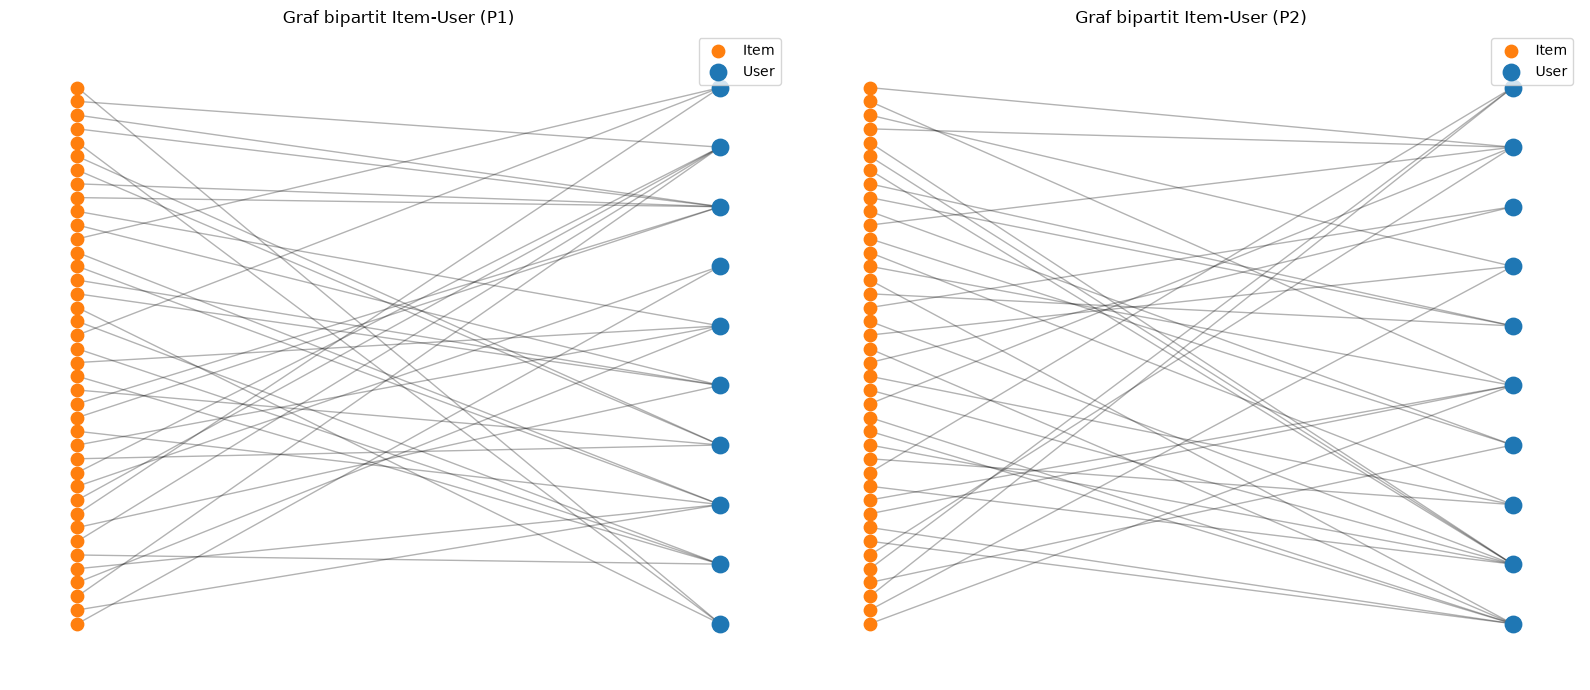

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, p in zip(axes, item_vsm):
    Xi, items, users = item_vsm[p]
    plot_item_sample(Xi, items, users, f"Graf bipartit Item-User ({p})", ax)
plt.tight_layout()
plt.show()

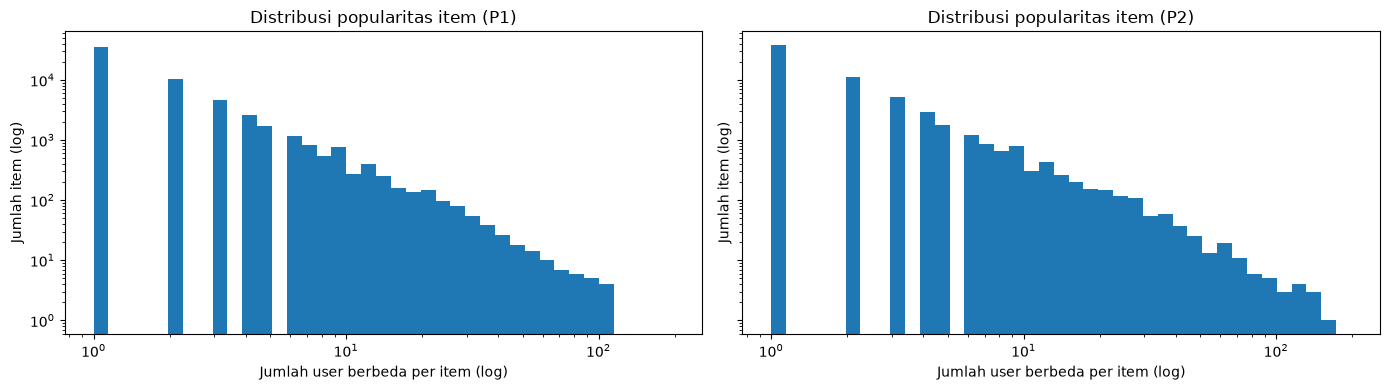

In [19]:
max_deg = max(np.diff(item_vsm[p][0].indptr).max() for p in item_vsm)
bins = np.logspace(0, np.log10(max_deg), 40)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True, sharey=True)
for ax, p in zip(axes, item_vsm):
    plot_degree_hist(item_vsm[p][0], f"Distribusi popularitas item ({p})", ax, bins,
                     "Jumlah user berbeda per item (log)", "Jumlah item (log)")
plt.tight_layout()
plt.show()

6. 

7. 

In [20]:
def binarize(M):
    B = M.copy().tocsr()
    B.data[:] = 1.0
    return B

Xi, items_p1, users_p1 = item_vsm["P1"]       # items x users (soal 5)
B = binarize(Xi)                               # biner
A = (B @ B.T).tocsr()                          # proyeksi berbobot: bobot = jumlah user bersama
deg = np.asarray(B.sum(axis=1)).ravel()        # jumlah user berbeda per item
n_items = A.shape[0]

print("Simpul proyeksi:", n_items)
print("Tepi proyeksi  :", (A.nnz - n_items) // 2)
print("Item terisolasi:", int((np.diff(A.indptr) == 1).sum()))

Simpul proyeksi: 59808
Tepi proyeksi  : 689945
Item terisolasi: 29342


In [21]:
def sim_row(i):
    s, e = A.indptr[i], A.indptr[i + 1]
    idx, inter = A.indices[s:e], A.data[s:e]
    keep = idx != i
    idx, inter = idx[keep], inter[keep]
    jac = inter / (deg[i] + deg[idx] - inter)
    return idx, inter, jac

def top_k(i, k):
    idx, inter, jac = sim_row(i)
    order = np.lexsort((items_p1[idx], -inter, -jac))[:k]   # urut: jaccard, shared, itemId
    return idx[order], inter[order], jac[order]

ref_idx = int(np.argmax(deg))
ref_item = int(items_p1[ref_idx])
idx, inter, jac = top_k(ref_idx, 5)
top5_py = pd.DataFrame({"itemId": items_p1[idx].astype(int),
                        "shared": inter.astype(int), "jaccard": jac})
print(f"Item acuan: {ref_item} ({int(deg[ref_idx])} user)")
top5_py

Item acuan: 309778 (198 user)


,itemId,shared,jaccard
0,257040,33,0.124060
1,360487,12,0.051502
2,115889,9,0.039648
3,223203,7,0.032710
4,258608,7,0.032558


In [22]:
PERIOD = "P1"

Q_TOP5 = """
MATCH (ref:Item {itemId: $ref})<-[r1]-(v:Visitor)
WHERE r1.period = $period
WITH ref, collect(DISTINCT v) AS refUsers
UNWIND refUsers AS v
MATCH (v)-[r2]->(other:Item)
WHERE r2.period = $period AND other <> ref
WITH ref, refUsers, other, count(DISTINCT v) AS shared
MATCH (other)<-[r3]-(u:Visitor)
WHERE r3.period = $period
WITH other, shared, size(refUsers) AS refDeg, count(DISTINCT u) AS otherDeg
RETURN other.itemId AS itemId,
       shared,
       toFloat(shared) / (refDeg + otherDeg - shared) AS jaccard
ORDER BY jaccard DESC, shared DESC, itemId ASC
LIMIT 5
"""

def run_query(session, query, **params):
    """Query baca -> list of dict. Hasil dikonsumsi DI DALAM transaction function."""
    return session.execute_read(lambda tx: tx.run(query, **params).data())

with driver.session(database="neo4j") as session:
    top5_cy = pd.DataFrame(run_query(session, Q_TOP5, ref=ref_item, period=PERIOD))
display(top5_cy)

assert len(top5_cy) == len(top5_py)
assert (top5_cy["itemId"].to_numpy() == top5_py["itemId"].to_numpy()).all()
assert np.allclose(top5_cy["jaccard"], top5_py["jaccard"])


C:\Users\Hype\AppData\Local\Temp\ipykernel_3340\384807177.py:25: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


,itemId,shared,jaccard
0,257040,33,0.124060
1,360487,12,0.051502
2,115889,9,0.039648
3,223203,7,0.032710
4,258608,7,0.032558


In [23]:
Q_WRITE = """
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.itemId})
MERGE (a)-[s:SIMILAR_TO {period: $period, metric: 'jaccard'}]->(b)
SET s.score = row.jaccard, s.shared_users = row.shared
"""
Q_SHOW = """
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO {period: $period}]->(b:Item)
RETURN a.itemId AS ref, b.itemId AS similar_item,
       s.score AS jaccard, s.shared_users AS shared_users, s.metric AS metric
ORDER BY s.score DESC, s.shared_users DESC, b.itemId ASC
"""
rows = top5_py.astype(object).to_dict(orient="records")

with driver.session(database="neo4j") as session:
    session.execute_write(lambda tx: tx.run(Q_WRITE, rows=rows, ref=ref_item, period=PERIOD).consume())
    result_after = pd.DataFrame(run_query(session, Q_SHOW, ref=ref_item, period=PERIOD))
result_after

C:\Users\Hype\AppData\Local\Temp\ipykernel_3340\2969142795.py:15: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


,ref,similar_item,jaccard,shared_users,metric
0,309778,257040,0.124060,33,jaccard
1,309778,360487,0.051502,12,jaccard
2,309778,115889,0.039648,9,jaccard
3,309778,223203,0.032710,7,jaccard
4,309778,258608,0.032558,7,jaccard


In [24]:
Q_COUNTS = "MATCH ()-[r]->() RETURN type(r) AS relationship, count(*) AS total ORDER BY relationship"
Q_NEIGH = """
MATCH (a:Item {itemId: $ref})<-[r1]-(v:Visitor)-[r2]->(b:Item)
WHERE r1.period = $period AND r2.period = $period AND b.itemId IN $top
RETURN DISTINCT v.visitorId AS visitor, b.itemId AS other
"""
top_ids = top5_py["itemId"].tolist()

with driver.session(database="neo4j") as session:
    before_counts = (pd.DataFrame(run_query(session, Q_COUNTS))
                     .set_index("relationship")["total"].rename("sebelum"))
    neigh = pd.DataFrame(run_query(session, Q_NEIGH, ref=ref_item, period=PERIOD, top=top_ids))
    n_sim_before = run_query(session, "MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n")[0]["n"]

print("Relasi SIMILAR_TO sebelum:", n_sim_before)
before_counts

C:\Users\Hype\AppData\Local\Temp\ipykernel_3340\3989909018.py:9: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


Relasi SIMILAR_TO sebelum: 5


relationship
ADDED_TO_CART     10055
BOUGHT             3373
CONTAINS           3341
MADE               2729
SIMILAR_TO            5
VIEWED           381723
Name: sebelum, dtype: int64

C:\Users\Hype\AppData\Local\Temp\ipykernel_3340\2390531773.py:1: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


,sebelum,sesudah,selisih
relationship,,,
ADDED_TO_CART,10055,10055,0
BOUGHT,3373,3373,0
CONTAINS,3341,3341,0
MADE,2729,2729,0
SIMILAR_TO,5,5,0
VIEWED,381723,381723,0


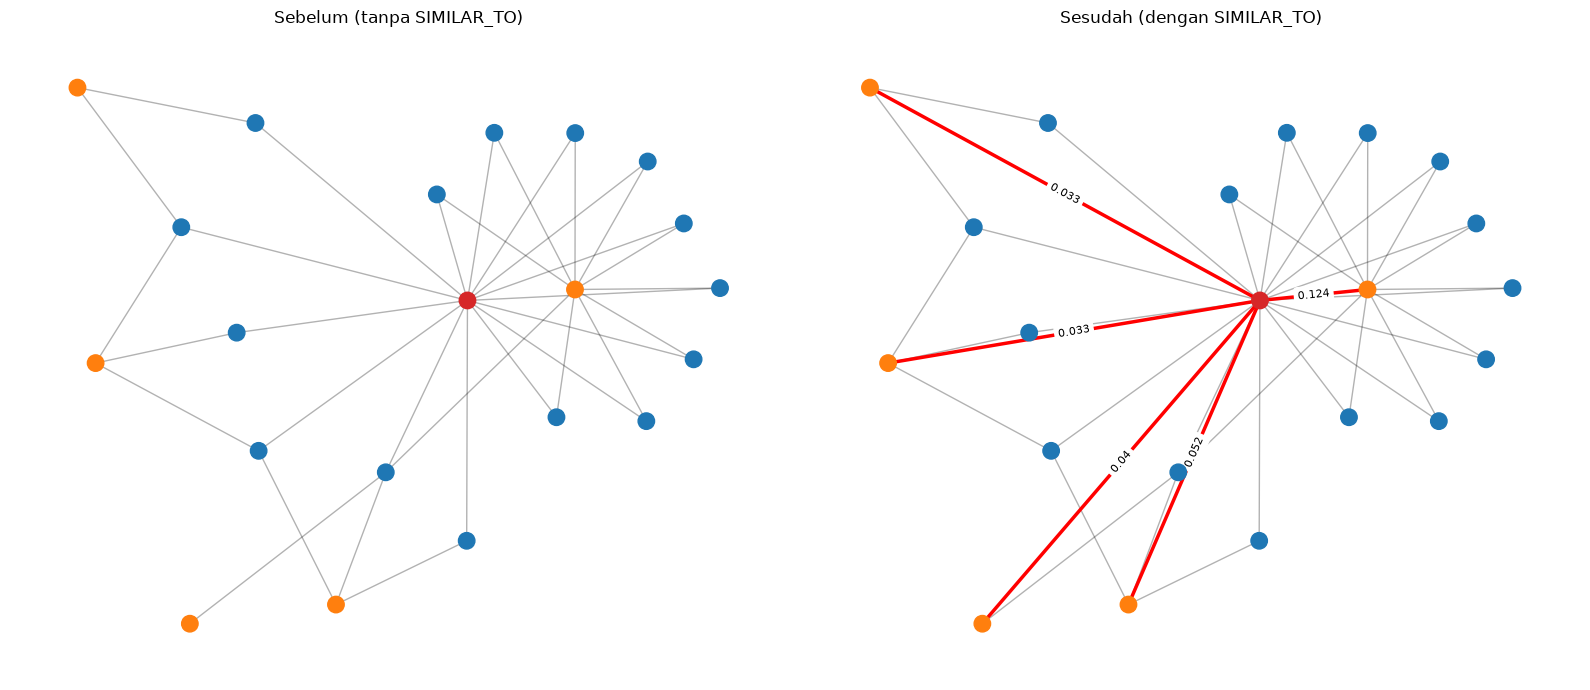

In [ ]:
with driver.session(database="neo4j") as session:
    after_counts = (pd.DataFrame(run_query(session, Q_COUNTS))
                    .set_index("relationship")["total"].rename("sesudah"))
comparison = pd.concat([before_counts, after_counts], axis=1).fillna(0).astype(int)
comparison["selisih"] = comparison["sesudah"] - comparison["sebelum"]
display(comparison)


rng = np.random.default_rng(42)
vis = np.array(sorted(neigh["visitor"].unique()))
vis = rng.choice(vis, size=min(15, len(vis)), replace=False)
sub = neigh[neigh["visitor"].isin(vis)]

ref_n = f"i{ref_item}"
G0 = nx.Graph()
G0.add_nodes_from([ref_n] + [f"i{i}" for i in top_ids])
for v in vis:
    G0.add_edge(f"u{v}", ref_n)
for _, r in sub.iterrows():
    G0.add_edge(f"u{r.visitor}", f"i{r.other}")

G1 = G0.copy()
sim_edges = {}
for _, r in result_after.iterrows():
    G1.add_edge(ref_n, f"i{r.similar_item}")
    sim_edges[(ref_n, f"i{r.similar_item}")] = round(float(r.jaccard), 3)
sim_set = set(sim_edges) | {(b, a) for a, b in sim_edges}

pos = nx.spring_layout(G0, seed=42)     # layout yang sama untuk kedua panel
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, G, title in zip(axes, [G0, G1], ["Sebelum (tanpa SIMILAR_TO)", "Sesudah (dengan SIMILAR_TO)"]):
    colors = ["tab:red" if n == ref_n else "tab:orange" if n.startswith("i") else "tab:blue"
              for n in G.nodes]
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=140, ax=ax)
    base = [e for e in G.edges if e not in sim_set]
    nx.draw_networkx_edges(G, pos, edgelist=base, alpha=0.3, ax=ax)
    if G is G1:
        nx.draw_networkx_edges(G, pos, edgelist=list(sim_edges), edge_color="red", width=2.5, ax=ax)
        nx.draw_networkx_edge_labels(G, pos, edge_labels=sim_edges, font_size=8, ax=ax)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 2.2 Analytics

In [26]:
SEED = 42
X1, users1, items1 = results["P1"]
X2, users2, items2 = results["P2"]
row1 = {int(u): i for i, u in enumerate(users1)}
row2 = {int(u): i for i, u in enumerate(users2)}
item_row = {int(it): i for i, it in enumerate(items_p1)}

def history(X, rowmap, items_arr, u):
    r = rowmap[u]
    cols = X.indices[X.indptr[r]:X.indptr[r + 1]]
    return set(int(x) for x in items_arr[cols])

def recommend(hist, k=5, n=5):
    scores = {}
    for it in hist:
        nb_idx, _, nb_sim = top_k(item_row[it], k)
        for j, s in zip(nb_idx, nb_sim):
            cand = int(items_p1[j])
            if cand in hist:
                continue
            scores[cand] = scores.get(cand, 0.0) + float(s)
    ranked = sorted(scores.items(), key=lambda kv: (-kv[1], kv[0]))
    return [i for i, _ in ranked[:n]], dict(ranked[:n])

# kandidat: user di P1 dan P2, punya riwayat P1, punya item baru di P2, dan bisa diberi >= 3 rekomendasi
common = np.intersect1d(users1, users2)
eligible = []
for u in common:
    u = int(u)
    h1 = history(X1, row1, items1, u)
    rel = history(X2, row2, items2, u) - h1
    if h1 and rel and len(recommend(h1)[0]) >= 3:
        eligible.append(u)
print("User di kedua periode:", len(common), "| memenuhi syarat:", len(eligible))

rng = np.random.default_rng(SEED)
target = int(rng.choice(np.array(sorted(eligible))))   # urut dulu agar reproducible
print("User terpilih:", target)

User di kedua periode: 4777 | memenuhi syarat: 1896
User terpilih: 123094


In [27]:
h1 = history(X1, row1, items1, target)
relevant = history(X2, row2, items2, target) - h1

rows_knn = []
for it in sorted(h1):
    nb_idx, nb_inter, nb_sim = top_k(item_row[it], 5)       # k = 5
    for j, sh, s in zip(nb_idx, nb_inter, nb_sim):
        rows_knn.append({"history_item": it, "neighbor": int(items_p1[j]),
                         "shared": int(sh), "jaccard": float(s)})
display(pd.DataFrame(rows_knn))

rec5, scores5 = recommend(h1, k=5, n=5)
rec3 = rec5[:3]
print("Riwayat P1 user :", sorted(h1))
print("3 item diiklankan:", rec3)
print("Skor             :", {i: round(scores5[i], 4) for i in rec3})

,history_item,neighbor,shared,jaccard
0,381508,160955,1,0.200000
1,381508,271890,1,0.100000
2,381508,390093,1,0.037037


Riwayat P1 user : [381508]
3 item diiklankan: [160955, 271890, 390093]
Skor             : {160955: 0.2, 271890: 0.1, 390093: 0.037}


In [28]:
def hit_at_k(ranked, rel, k=5):
    return int(any(i in rel for i in ranked[:k]))

def dcg_at_k(ranked, rel, k=5):
    return sum(1.0 / np.log2(p + 2) for p, i in enumerate(ranked[:k]) if i in rel)

def ndcg_at_k(ranked, rel, k=5):
    ideal = sum(1.0 / np.log2(p + 2) for p in range(min(len(rel), k)))
    return dcg_at_k(ranked, rel, k) / ideal if ideal > 0 else 0.0

print("Item relevan (P2 baru):", sorted(relevant))
print("Relevan yang ada di semesta item P1:", len(relevant & set(item_row)), "dari", len(relevant))
for name, lst in [("3 item diiklankan", rec3), ("Top-5", rec5)]:
    print(f"{name}: {lst} | Hit@5 = {hit_at_k(lst, relevant)} | "
          f"DCG@5 = {dcg_at_k(lst, relevant):.4f} | NDCG@5 = {ndcg_at_k(lst, relevant):.4f}")

# --- pembanding: rata-rata atas semua user memenuhi syarat + baseline popularitas ---
pop_order = np.lexsort((items_p1, -deg))
def recommend_pop(hist, n=5):
    out = []
    for r in pop_order:
        it = int(items_p1[r])
        if it not in hist:
            out.append(it)
        if len(out) == n:
            break
    return out

def evaluate(users, fn):
    H, N = [], []
    for u in users:
        h = history(X1, row1, items1, u)
        r = history(X2, row2, items2, u) - h
        rec = fn(h)
        H.append(hit_at_k(rec, r)); N.append(ndcg_at_k(rec, r))
    return round(float(np.mean(H)), 4), round(float(np.mean(N)), 4)

print("Item-kNN  (rata-rata Hit@5, NDCG@5):", evaluate(eligible, lambda h: recommend(h, 5, 5)[0]))
print("Populer   (rata-rata Hit@5, NDCG@5):", evaluate(eligible, recommend_pop))

Item relevan (P2 baru): [255344, 262644]
Relevan yang ada di semesta item P1: 2 dari 2
3 item diiklankan: [160955, 271890, 390093] | Hit@5 = 0 | DCG@5 = 0.0000 | NDCG@5 = 0.0000
Top-5: [160955, 271890, 390093] | Hit@5 = 0 | DCG@5 = 0.0000 | NDCG@5 = 0.0000
Item-kNN  (rata-rata Hit@5, NDCG@5): (0.0738, 0.0402)
Populer   (rata-rata Hit@5, NDCG@5): (0.0084, 0.0034)
